# 코드 B · 보험사기·피싱 탐지 데이터 점검
**핀테크 데이터 분석 : 실제로 해보는 데이터 분석편 #01**  
원본: [fintech-data/Revolution2](https://github.com/fintech-data/Revolution2) `Loading_Data.ipynb` → 이 폴더의 `original_Loading_Data.ipynb`  
해설 페이지: https://adminmrobo.github.io/fintech_data_analysis/hands_on_01.html

> 코드를 몰라도 괜찮아요. 위에서부터 ▶ 실행 버튼만 차례로 누르면 됩니다.

## 이 코드가 하는 일
가짜 웹사이트(피싱)와 허위 보험금 청구를 가려내는 데 쓸 **표 네 개를 불러오고 `info()`로 건강검진**을 합니다.

> 비유: 은행 창구 직원이 "수상한 서류 묶음"을 받아 우선 장수와 빈 값부터 세어 보는 일.

원본에서 여행자보험 표를 `insurance_claim`이라는 이름에 다시 담아 앞의 청구 표를 덮어쓰는 부분이 있어, 여기서는 `travel_insurance`로 이름을 바꿨습니다.

In [1]:
import os, io, urllib.request
import pandas as pd
pd.set_option('display.max_columns', 12); pd.set_option('display.width', 120)

# 데이터 위치: 이 폴더의 data/ 에 있으면 그걸 쓰고, 없으면(Colab 등) GitHub에서 바로 읽습니다.
RAW = 'https://raw.githubusercontent.com/adminmrobo/fintech_data_analysis/main/hands_on/01/B_fraud_phishing_check/data/'
def load(name, **kw):
    local = os.path.join('data', name)
    src = local if os.path.exists(local) else RAW + urllib.parse.quote(name)
    return pd.read_csv(src, low_memory=False, **kw)
print('준비 완료')

준비 완료


In [2]:
website_phishing = load('Website Phishing.csv')
print(website_phishing.shape)
# Result: 1 정상 / 0 의심 / -1 피싱
website_phishing['Result'].value_counts()

(1353, 10)


Result
-1    702
 1    548
 0    103
Name: count, dtype: int64

In [3]:
website_phishing.info()

<class 'pandas.DataFrame'>
RangeIndex: 1353 entries, 0 to 1352
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   SFH                1353 non-null   int64
 1   popUpWidnow        1353 non-null   int64
 2   SSLfinal_State     1353 non-null   int64
 3   Request_URL        1353 non-null   int64
 4   URL_of_Anchor      1353 non-null   int64
 5   web_traffic        1353 non-null   int64
 6   URL_Length         1353 non-null   int64
 7   age_of_domain      1353 non-null   int64
 8   having_IP_Address  1353 non-null   int64
 9   Result             1353 non-null   int64
dtypes: int64(10)
memory usage: 105.8 KB


In [4]:
insurance = load('insurance.csv')
insurance.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [5]:
insurance_claim = load('insurance_claims.csv')
print(insurance_claim.shape)
insurance_claim['fraud_reported'].value_counts()

(1000, 39)


fraud_reported
N    753
Y    247
Name: count, dtype: int64

In [6]:
# 빈 값은 NaN 말고 '?'로도 숨어 있습니다
print('NaN 빈 값:', insurance_claim.isna().sum()[lambda s: s > 0].to_dict())
print("'?' 빈 값:", {c: int((insurance_claim[c] == '?').sum()) for c in insurance_claim.columns if (insurance_claim[c] == '?').any()})

NaN 빈 값: {'authorities_contacted': 91}
'?' 빈 값: {'collision_type': 178, 'property_damage': 360, 'police_report_available': 343}


In [7]:
# 사고 심각도별 허위 청구 비율
(insurance_claim['fraud_reported'] == 'Y').groupby(insurance_claim['incident_severity']).mean().round(3)

incident_severity
Major Damage      0.605
Minor Damage      0.107
Total Loss        0.129
Trivial Damage    0.067
Name: fraud_reported, dtype: float64

In [8]:
travel_insurance = load('travel insurance.csv')  # 원본은 이 표를 insurance_claim에 덮어썼어요
travel_insurance.shape

(63326, 11)

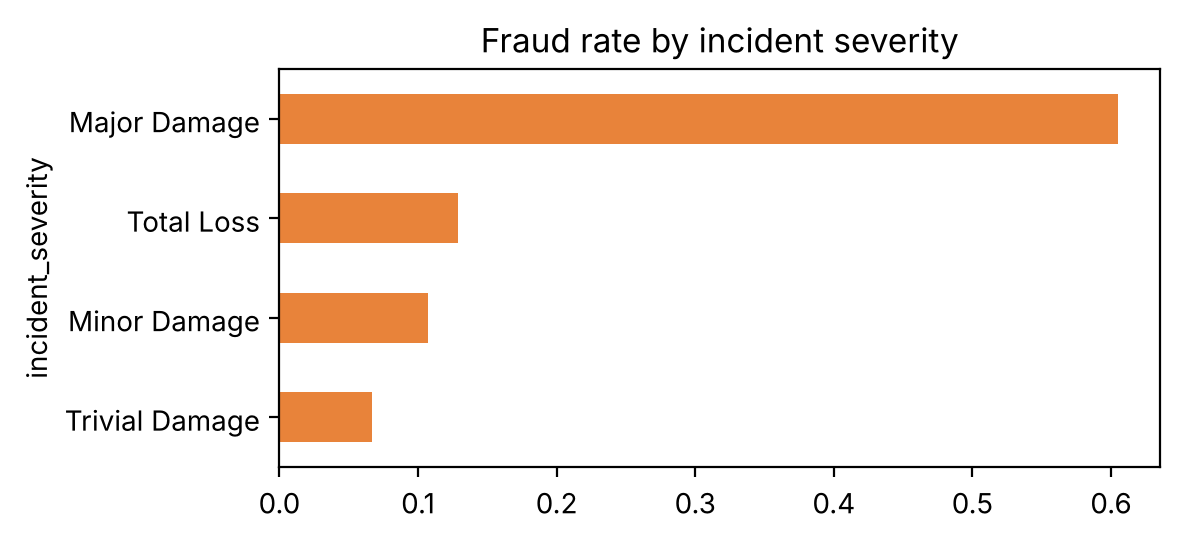

In [9]:
import matplotlib.pyplot as plt
r = (insurance_claim['fraud_reported'] == 'Y').groupby(insurance_claim['incident_severity']).mean()
r.sort_values().plot.barh(color='#e8833a', title='Fraud rate by incident severity', figsize=(6, 2.8)); plt.tight_layout(); plt.show()